In [1]:
import warnings

import optuna
import pandas as pd
import seaborn as sns
from mpmath.math2 import math_sqrt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import cross_val_score, LearningCurveDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor
from pyspark.sql import SparkSession

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

/home/vagno/Desktop/velib-paris/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
spark = SparkSession.builder \
    .appName("Velib_Model_Training") \
    .getOrCreate()


OUTPUT_PATH = "hdfs://localhost:9000/user/hadoop/data/data_with_meteo_final"
spark_df = spark.read.parquet(OUTPUT_PATH)

spark_df.printSchema()
spark_df.show(5)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
25/12/28 17:55:09 WARN Utils: Your hostname, yassi, resolves to a loopback address: 127.0.1.1; using 10.188.31.196 instead (on interface wlp59s0)
25/12/28 17:55:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/28 17:55:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
25/12/28 17:55:13 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


root
 |-- stationcode: string (nullable = true)
 |-- name: string (nullable = true)
 |-- is_installed: string (nullable = true)
 |-- capacity: long (nullable = true)
 |-- numdocksavailable: long (nullable = true)
 |-- numbikesavailable: long (nullable = true)
 |-- mechanical: long (nullable = true)
 |-- ebike: long (nullable = true)
 |-- is_renting: string (nullable = true)
 |-- is_returning: string (nullable = true)
 |-- duedate: timestamp (nullable = true)
 |-- coordonnees_geo: struct (nullable = true)
 |    |-- lat: double (nullable = true)
 |    |-- lon: double (nullable = true)
 |-- nom_arrondissement_communes: string (nullable = true)
 |-- code_insee_commune: string (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- rain: double (nullable = true)
 |-- snowfall: double (nullable = true)
 |-- relative_humidity_2m: double (nullable = true)
 |-- is_holiday: integer (nullable = true)
 |-- hour: integer (nullable = true)
 |

25/12/28 17:55:30 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-----------+--------------------+------------+--------+-----------------+-----------------+----------+-----+----------+------------+-------------------+--------------------+---------------------------+------------------+--------------+-------------+----+--------+--------------------+----------+----+-----+---------+----------+--------+--------------------+-------------------+------------------+-------------------+-------------------+----------+
|stationcode|                name|is_installed|capacity|numdocksavailable|numbikesavailable|mechanical|ebike|is_renting|is_returning|            duedate|     coordonnees_geo|nom_arrondissement_communes|code_insee_commune|temperature_2m|precipitation|rain|snowfall|relative_humidity_2m|is_holiday|hour|month|dayofweek|is_weekend|hour_sin|            hour_cos|            dow_sin|           dow_cos|        bikes_ratio|        docks_ratio|is_raining|
+-----------+--------------------+------------+--------+-----------------+-----------------+----------

In [3]:
df = df = spark_df.toPandas()
df.head()

,stationcode,name,is_installed,capacity,numdocksavailable,numbikesavailable,mechanical,ebike,is_renting,is_returning,duedate,coordonnees_geo,nom_arrondissement_communes,code_insee_commune,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,is_holiday,hour,month,dayofweek,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,bikes_ratio,docks_ratio,is_raining
0,16107,Benjamin Godard - Victor Hugo,OUI,35.0,30,4,2,2,OUI,OUI,2025-12-17 06:26:32,"(48.865983, 2.275725)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.114286,0.857143,0
1,40001,Hôpital Mondor,OUI,28.0,12,17,2,15,OUI,OUI,2025-12-17 06:33:29,"(48.798922410229, 2.4537451531298)",Créteil,94028,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.607143,0.428571,0
2,32304,Charcot - Benfleet,OUI,28.0,22,4,2,2,OUI,OUI,2025-12-17 06:28:10,"(48.878370277021, 2.440523876268)",Romainville,93063,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.142857,0.785714,0
3,11104,Charonne - Robert et Sonia Delaunay,OUI,20.0,12,8,1,7,OUI,OUI,2025-12-17 06:32:00,"(48.855907555969, 2.3925706744194)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.400000,0.600000,0
4,8026,Messine - Place Du Pérou,OUI,12.0,7,4,4,0,OUI,OUI,2025-12-17 06:33:20,"(48.875448033960744, 2.315508019010038)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.333333,0.583333,0


In [4]:
targets = ['numbikesavailable', 'numdocksavailable']

drop_cols = ['duedate', 'numbikesavailable', 'numdocksavailable', 'nom_arrondissement_communes','is_returning', 'coordonnees_geo', 'is_renting', 'is_installed', 'code_insee_commune']

categorical_features = ['is_weekend']
numeric_features = [col for col in df.columns
                    if col not in drop_cols + targets + categorical_features]

X = df.drop(columns=drop_cols + targets)
y = df[targets]

# --- SPLIT TEMPOREL ---
train_size = int(len(df) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"\nTrain set : {X_train.shape}")
print(f"Test set  : {X_test.shape}")


Train set : (143336, 22)
Test set  : (35834, 22)


In [5]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns
categorical_features

Index(['stationcode', 'name'], dtype='object')

In [6]:
numeric_features = X.select_dtypes(exclude=['object']).columns


def create_preprocessor(num_features, cat_features):
    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ('scaler', StandardScaler())
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]
    )

    pipeline = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, num_features),
            ("cat", categorical_transformer, cat_features),
        ]
    )

    return pipeline

In [12]:
leakage_cols = [
    'bikes_ratio',
    'docks_ratio',
    'mechanical',
    'ebike',
    'fill_rate'
]

# Récupérez vos listes de features initiales (Numeric et Categorical)
all_columns = X_train.columns.tolist()

# Filtrage : On garde tout ce qui n'est PAS dans la liste noire
features_to_keep = [c for c in all_columns if c not in leakage_cols]

numeric_features_clean = X_train[features_to_keep].select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features_clean = X_train[features_to_keep].select_dtypes(
    include=['object', 'category', 'bool']).columns.tolist()

new_preprocessor = create_preprocessor(numeric_features_clean, categorical_features_clean)
# Entraînement sur les données propres (en supprimant les colonnes du DF aussi pour être cohérent)
X_train_clean = X_train[features_to_keep]
X_test_clean = X_test[features_to_keep]

In [13]:
def objective(trial):
    hyper_params = {
        "n_estimators": trial.suggest_int("n_estimators", 600, 800),
        "max_depth": trial.suggest_int("max_depth", 7, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.2, 0.3, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 5, 9),
        "reg_lambda": trial.suggest_float("reg_lambda", 1, 20, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 40, 70),
        "subsample": trial.suggest_float("subsample", 0.5, 0.8),
        "gamma": trial.suggest_float("gamma", 7, 9),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.8, 1.0),
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBRegressor(**hyper_params, device='gpu')

    pipeline = Pipeline(
        steps=[
            ('preprocessor', new_preprocessor),
            ('model', model)
        ]
    )

    pipeline.fit(X_train_clean, y_train)

    y_pred = pipeline.predict(X_test_clean)

    return r2_score(y_test, y_pred)

In [9]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(),
                            pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=50, n_jobs=1)

best_params = study.best_params
best_params

[I 2025-12-28 17:56:16,118] A new study created in memory with name: no-name-82358d6a-179b-45a2-b2ea-09991c4a92ee
[I 2025-12-28 17:57:03,271] Trial 0 finished with value: 0.6712030172348022 and parameters: {'n_estimators': 794, 'max_depth': 9, 'learning_rate': 0.2632899365185872, 'min_child_weight': 9, 'reg_lambda': 10.955170927055473, 'reg_alpha': 58.32522008638476, 'subsample': 0.6709454080207965, 'gamma': 8.49370264383897, 'colsample_bytree': 0.8218502040733623}. Best is trial 0 with value: 0.6712030172348022.
[I 2025-12-28 17:57:32,521] Trial 1 finished with value: 0.6466928720474243 and parameters: {'n_estimators': 759, 'max_depth': 7, 'learning_rate': 0.29415177510306395, 'min_child_weight': 7, 'reg_lambda': 16.728044927793185, 'reg_alpha': 69.05769237546258, 'subsample': 0.5878996496894017, 'gamma': 7.227803002520321, 'colsample_bytree': 0.8361783250392844}. Best is trial 0 with value: 0.6712030172348022.
[I 2025-12-28 17:58:05,729] Trial 2 finished with value: 0.679310083389282

{'n_estimators': 663,
 'max_depth': 10,
 'learning_rate': 0.2994899261168135,
 'min_child_weight': 6,
 'reg_lambda': 1.3032372341666711,
 'reg_alpha': 40.30776941855407,
 'subsample': 0.6311335719515618,
 'gamma': 7.536046908934834,
 'colsample_bytree': 0.9947868103011563}

R2 0.7098308205604553
MSE 39.24848175048828
RMSE 6.264860872396791
MAE 4.603778839111328


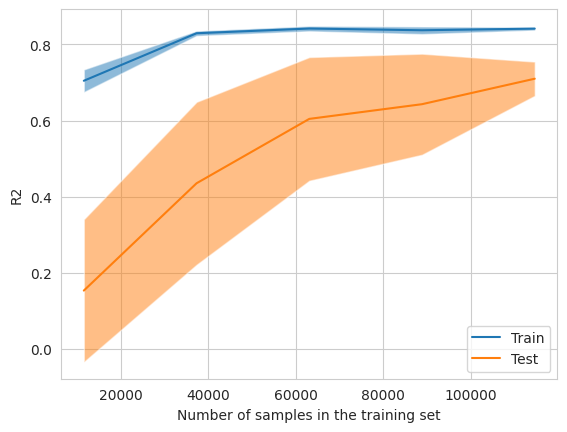

In [20]:
from datetime import datetime
import joblib

final_model = XGBRegressor(**best_params, device='gpu', verbosity=1, random_state=42)

pipeline = Pipeline(
    steps=[
        ('preprocessor', new_preprocessor),
        ('model', final_model)
    ]
)

pipeline.fit(X_train_clean, y_train)

LearningCurveDisplay.from_estimator(pipeline, X_train_clean, y_train, cv=5, scoring='r2', random_state=42, verbose=0)

pred = pipeline.predict(X_test_clean)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
joblib.dump(pipeline, f"pipeline_{timestamp}.pkl")

print(f'R2 {r2_score(y_test, pred)}')
print(f'MSE {mean_squared_error(y_test, pred)}')
print(f'RMSE {math_sqrt(mean_squared_error(y_test, pred))}')
print(f'MAE {mean_absolute_error(y_test, pred)}')

In [22]:
loaded_pipeline = joblib.load("pipeline_latest.pkl")
pred = loaded_pipeline.predict(X_test_clean)

pred

array([[13.662531 ,  9.531871 ],
       [ 2.5223064, 62.86124  ],
       [ 5.431559 , 24.492928 ],
       ...,
       [ 7.599387 , 32.568214 ],
       [15.365541 , 12.41083  ],
       [ 4.6244483, 10.381189 ]], shape=(35834, 2), dtype=float32)